Predicting Optimal Planting Seasons for Major Bangladeshi Crops Using Machine Learning and Historical Weather Patterns

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import folium
from glob import glob

import math

import librosa
import librosa.display
import IPython.display as ipd

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.model_selection import cross_val_score

from sklearn.decomposition import PCA, FastICA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
import xgboost as xgb
from sklearn.utils.class_weight import compute_sample_weight

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
agr = pd.read_csv("/content/drive/MyDrive/Optimal Planting Seasons/agricultural_data.csv")

In [5]:
agr.head()

,Transplant,Products name,Crops Type,Max Temp,Min Temp,Min Relative Humidity,Max Relative Humidity,Transplant_en
0,March,Aus Rice(Local: Broadcasted),Cereals,40.0,12.0,60,85,3
1,March,Aus Rice(HYV: Transplant),Cereals,40.0,12.0,60,85,3
2,March,Maize 2,Cereals,34.0,20.0,60,85,3
3,Feb,Mungbean 2,Pulses,30.0,20.0,20,85,2
4,July,Soybean 2,Oil Seeds,35.0,15.0,35,80,7


In [6]:
agr.shape

(103, 8)

In [7]:
agr.columns

Index(['Transplant', 'Products name', 'Crops Type', 'Max Temp', 'Min Temp',
       'Min Relative Humidity', 'Max Relative Humidity', 'Transplant_en'],
      dtype='object')

In [8]:
agr['Products name'].nunique()

103

In [9]:
agr["Transplant"].nunique()

12

In [10]:
agr['Crops Type'].unique()

array(['Cereals', 'Pulses', 'Oil Seeds', 'Vegetables', 'Fibre', 'Staple',
       'Fruits', 'Tubers', 'Nicotine'], dtype=object)

In [11]:
agr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103 entries, 0 to 102
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Transplant             103 non-null    object 
 1   Products name          103 non-null    object 
 2   Crops Type             103 non-null    object 
 3   Max Temp               103 non-null    float64
 4   Min Temp               103 non-null    float64
 5   Min Relative Humidity  103 non-null    int64  
 6   Max Relative Humidity  103 non-null    int64  
 7   Transplant_en          103 non-null    int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 6.6+ KB


In [12]:
agriculture = agr.iloc[:,1:]

In [13]:
agriculture.head()

,Products name,Crops Type,Max Temp,Min Temp,Min Relative Humidity,Max Relative Humidity,Transplant_en
0,Aus Rice(Local: Broadcasted),Cereals,40.0,12.0,60,85,3
1,Aus Rice(HYV: Transplant),Cereals,40.0,12.0,60,85,3
2,Maize 2,Cereals,34.0,20.0,60,85,3
3,Mungbean 2,Pulses,30.0,20.0,20,85,2
4,Soybean 2,Oil Seeds,35.0,15.0,35,80,7


In [14]:
Y = agr.iloc[:, 7:]

In [15]:
Y.head()

,Transplant_en
0,3
1,3
2,3
3,2
4,7


In [16]:
temp = pd.read_csv("/content/drive/MyDrive/Optimal Planting Seasons/BD_weather.csv")

In [17]:
temp.head()

,Station,Year,Month,Day,Rainfall,Sunshine,Humidity,Temperature
0,Ambaganctg,2008,1,1,0.0,9.1,78.0,20.1
1,Ambaganctg,2008,1,2,0.0,5.6,79.0,21.0
2,Ambaganctg,2008,1,3,0.0,8.6,82.0,20.1
3,Ambaganctg,2008,1,4,0.0,9.1,73.0,21.0
4,Ambaganctg,2008,1,5,0.0,9.4,67.0,20.3


In [18]:
data= temp[(temp["Year"] == 2023) & (temp["Month"] == 12)]['Humidity'].mean()
data

np.float64(80.79447004608295)

In [19]:
temp.columns

Index(['Station', 'Year', 'Month', 'Day', 'Rainfall', 'Sunshine', 'Humidity',
       'Temperature'],
      dtype='object')

<Axes: >

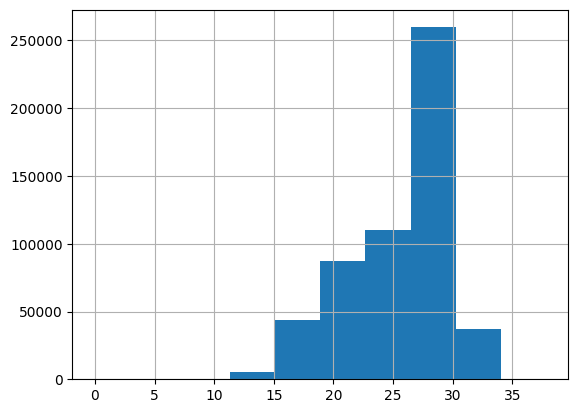

In [20]:
temp['Temperature'].hist()

In [21]:
temp['Temperature'].mean()

np.float64(25.570679888717066)

In [22]:
temp.Station.nunique()

35

In [23]:
temp.Year.nunique()

63

In [24]:
temp.Year.min()

1961

In [25]:
class_labels = agr['Transplant'].unique()

In [26]:
class_labels

array(['March', 'Feb', 'July', 'May', 'June', 'April', 'Nov', 'Dec',
       'Sep', 'Oct', 'Jan', 'Aug'], dtype=object)

In [27]:
class_label = np.array(["January", "February", "March", "April", "May", "June", "July", "August", "September","October", "November", "December"])

### Model 1 (30 years data based on Station)

In [28]:
temp_modify = temp.groupby(["Station","Year","Month"], as_index = False).agg({'Rainfall' : "mean", 'Sunshine': "mean", 'Humidity': "mean",
       'Temperature': "mean"})

In [29]:
temp_modify.shape

(17868, 7)

In [30]:
temp_modify = temp_modify[(temp_modify["Year"] >= 1994) & (temp_modify["Year"] <= 2023)]
station_count = temp_modify["Station"].value_counts()
station_to_keep = station_count[station_count == 360].index
temp_30 = temp_modify[temp_modify["Station"].isin(station_to_keep)]

In [31]:
temp_30.head()

,Station,Year,Month,Rainfall,Sunshine,Humidity,Temperature
516,Barisal,1994,1,0.129032,7.716129,78.129032,18.554839
517,Barisal,1994,2,0.464286,7.771429,75.642857,20.571429
518,Barisal,1994,3,2.967742,8.132258,77.161290,26.438710
519,Barisal,1994,4,3.366667,7.960000,79.533333,27.963333
520,Barisal,1994,5,5.741935,7.454839,83.935484,29.116129


In [32]:
XY = temp_30.merge(agriculture, how = "left", left_on = "Month", right_on = 'Transplant_en')

In [33]:
XY.shape

(95790, 14)

In [34]:
XY.head()

,Station,Year,Month,Rainfall,Sunshine,Humidity,Temperature,Products name,Crops Type,Max Temp,Min Temp,Min Relative Humidity,Max Relative Humidity,Transplant_en
0,Barisal,1994,1,0.129032,7.716129,78.129032,18.554839,Lemon,Fruits,25.0,10.0,60,95,1
1,Barisal,1994,1,0.129032,7.716129,78.129032,18.554839,Banana,Fruits,35.0,15.0,75,85,1
2,Barisal,1994,1,0.129032,7.716129,78.129032,18.554839,Okra,Vegetables,29.0,20.0,70,95,1
3,Barisal,1994,2,0.464286,7.771429,75.642857,20.571429,Mungbean 2,Pulses,30.0,20.0,20,85,2
4,Barisal,1994,2,0.464286,7.771429,75.642857,20.571429,Onion 2,Vegetables,30.0,20.0,65,75,2


In [35]:
XY.columns

Index(['Station', 'Year', 'Month', 'Rainfall', 'Sunshine', 'Humidity',
       'Temperature', 'Products name', 'Crops Type', 'Max Temp', 'Min Temp',
       'Min Relative Humidity', 'Max Relative Humidity', 'Transplant_en'],
      dtype='object')

In [36]:
XY_final = XY.loc[:,['Station', 'Year', 'Rainfall', 'Sunshine', 'Humidity',
       'Temperature', 'Products name', 'Crops Type', 'Max Temp', 'Min Temp',
       'Max Relative Humidity', 'Min Relative Humidity', 'Transplant_en']]

In [37]:
XY_final.head()

,Station,Year,Rainfall,Sunshine,Humidity,Temperature,Products name,Crops Type,Max Temp,Min Temp,Max Relative Humidity,Min Relative Humidity,Transplant_en
0,Barisal,1994,0.129032,7.716129,78.129032,18.554839,Lemon,Fruits,25.0,10.0,95,60,1
1,Barisal,1994,0.129032,7.716129,78.129032,18.554839,Banana,Fruits,35.0,15.0,85,75,1
2,Barisal,1994,0.129032,7.716129,78.129032,18.554839,Okra,Vegetables,29.0,20.0,95,70,1
3,Barisal,1994,0.464286,7.771429,75.642857,20.571429,Mungbean 2,Pulses,30.0,20.0,85,20,2
4,Barisal,1994,0.464286,7.771429,75.642857,20.571429,Onion 2,Vegetables,30.0,20.0,75,65,2


In [38]:
XY_final["Station"].unique()

array(['Barisal', 'Bhola', 'Bogra', 'Chandpur', 'Chittagong', 'Comilla',
       'Coxsbazar', 'Dhaka', 'Dinajpur', 'Faridpur', 'Feni', 'Hatiya',
       'Ishurdi', 'Jessore', 'Khepupara', 'Khulna', 'Kutubdia',
       'Madaripur', 'Mcourt', 'Mymensingh', 'Patuakhali', 'Rajshahi',
       'Rangamati', 'Rangpur', 'Sandwip', 'Satkhira', 'Sitakunda',
       'Srimangal', 'Sylhet', 'Tangail', 'Teknaf'], dtype=object)

Data Preprocessing

In [39]:
le_product = LabelEncoder()
XY_final['Products_encoded'] = le_product.fit_transform(XY_final['Products name'])

le_crop = LabelEncoder()
XY_final['CropType_encoded'] = le_crop.fit_transform(XY_final['Crops Type'])

le_station = LabelEncoder()
XY_final['Station_encoded'] = le_station.fit_transform(XY_final['Station'])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(XY_final[['Rainfall', 'Sunshine', 'Humidity', 'Temperature',
                                                 'Max Temp', 'Min Temp','Max Relative Humidity', 'Min Relative Humidity',
                                                 'Products_encoded','CropType_encoded','Station_encoded']])
Y = XY_final['Transplant_en']

# split data
x_train, x_test, y_train, y_test = train_test_split(scaled_features, Y, test_size=0.2, random_state=203, stratify= Y)

KNN

In [40]:
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(x_train, y_train)

KNN_test = knn.predict(x_test)

print("Classification Report:\n", classification_report(y_test, KNN_test))

Classification Report:
               precision    recall  f1-score   support

           1       1.00      1.00      1.00       558
           2       1.00      1.00      1.00      1116
           3       0.98      0.99      0.99      2046
           4       0.99      0.98      0.99      3348
           5       0.91      0.84      0.88       186
           6       1.00      0.99      1.00       558
           7       0.99      1.00      0.99       744
           8       1.00      1.00      1.00       930
           9       0.99      1.00      0.99      3720
          10       0.99      0.99      0.99      3720
          11       1.00      0.99      0.99      1488
          12       1.00      1.00      1.00       744

    accuracy                           0.99     19158
   macro avg       0.99      0.98      0.98     19158
weighted avg       0.99      0.99      0.99     19158



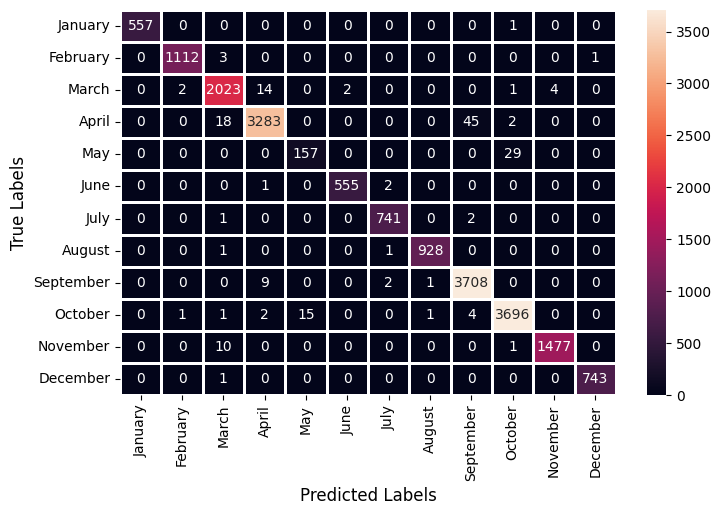

In [41]:
cf_matrix = confusion_matrix(y_test, KNN_test)
fig, ax = plt.subplots(figsize=(8,5))
sns.heatmap(cf_matrix, linewidths=1, annot=True, ax=ax, fmt='g')
ax.set_xticklabels(class_label, rotation = 90)
ax.set_yticklabels(class_label, rotation = 360)
ax.set_xlabel("Predicted Labels", fontsize=12)
ax.set_ylabel("True Labels", fontsize=12)
plt.show()

Decision Tree Classifier

In [42]:
clf = DecisionTreeClassifier(random_state=0, max_depth = 6)
clf.fit(x_train, y_train)

Dtree_test = clf.predict(x_test)

print("Classification Report:\n", classification_report(y_test, Dtree_test))

Classification Report:
               precision    recall  f1-score   support

           1       0.97      0.99      0.98       558
           2       0.93      0.94      0.94      1116
           3       0.77      0.85      0.81      2046
           4       0.90      0.88      0.89      3348
           5       1.00      0.59      0.74       186
           6       0.99      0.63      0.77       558
           7       0.86      0.54      0.66       744
           8       0.86      0.38      0.53       930
           9       0.66      0.94      0.77      3720
          10       0.86      0.74      0.80      3720
          11       0.94      0.78      0.86      1488
          12       0.92      0.99      0.95       744

    accuracy                           0.82     19158
   macro avg       0.89      0.77      0.81     19158
weighted avg       0.84      0.82      0.81     19158



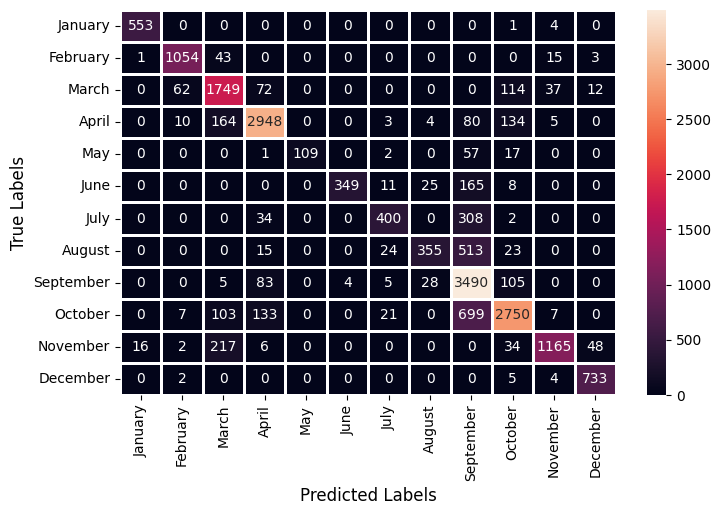

In [43]:
cf_matrix = confusion_matrix(y_test, Dtree_test)
fig, ax = plt.subplots(figsize=(8,5))
sns.heatmap(cf_matrix, linewidths=1, annot=True, ax=ax, fmt='g')
ax.set_xticklabels(class_label, rotation = 90)
ax.set_yticklabels(class_label, rotation = 360)
ax.set_xlabel("Predicted Labels", fontsize=12)
ax.set_ylabel("True Labels", fontsize=12)
plt.show()

Random Forest

In [44]:
rf_model = RandomForestClassifier(n_estimators=50, random_state=40)
rf_model.fit(x_train, y_train)

rf_test = rf_model.predict(x_test)

print("Classification Report:\n", classification_report(y_test, rf_test))

Classification Report:
               precision    recall  f1-score   support

           1       1.00      1.00      1.00       558
           2       1.00      1.00      1.00      1116
           3       1.00      1.00      1.00      2046
           4       1.00      1.00      1.00      3348
           5       1.00      1.00      1.00       186
           6       1.00      1.00      1.00       558
           7       1.00      1.00      1.00       744
           8       1.00      1.00      1.00       930
           9       1.00      1.00      1.00      3720
          10       1.00      1.00      1.00      3720
          11       1.00      1.00      1.00      1488
          12       1.00      1.00      1.00       744

    accuracy                           1.00     19158
   macro avg       1.00      1.00      1.00     19158
weighted avg       1.00      1.00      1.00     19158



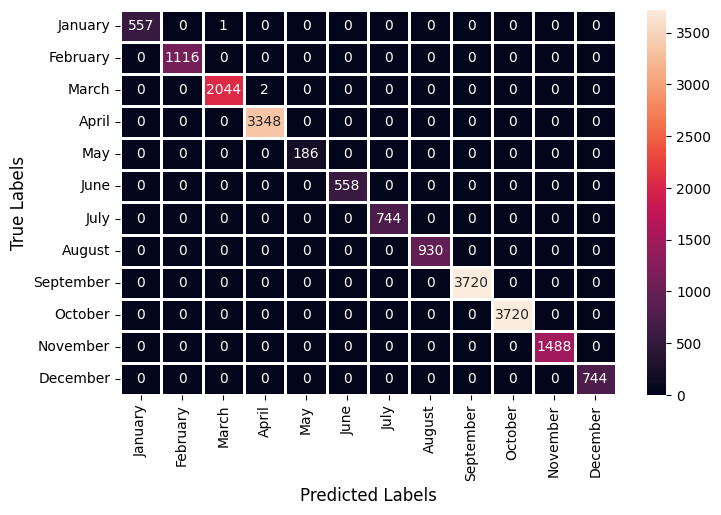

In [45]:
cf_matrix = confusion_matrix(y_test, rf_test)
fig, ax = plt.subplots(figsize=(8,5))
sns.heatmap(cf_matrix, linewidths=1, annot=True, ax=ax, fmt='g')
ax.set_xticklabels(class_label, rotation = 90)
ax.set_yticklabels(class_label, rotation = 360)
ax.set_xlabel("Predicted Labels", fontsize=12)
ax.set_ylabel("True Labels", fontsize=12)
plt.show()

In [46]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier

X, y = scaled_features, Y

# K-Fold Cross Validation
k = 5
kf = KFold(n_splits=k, shuffle=True, random_state=42)

# Initialize the RandomForestClassifier model
model = RandomForestClassifier(n_estimators=50, random_state=40)

# Perform Cross Validation
scores = cross_val_score(model, X, y, cv=kf, scoring='accuracy')

print(f"Accuracy for each fold: {scores}")

average_accuracy = np.mean(scores)
print(f"Average Accuracy: {average_accuracy:.2f}")

Accuracy for each fold: [0.99979121 0.9998956  0.9998956  0.99979121 0.9999478 ]
Average Accuracy: 1.00


### Model 2 (30 years data based on Station)

In [47]:
XY_target = XY.loc[:,['Station', 'Year', 'Rainfall', 'Sunshine', 'Humidity',
       'Temperature', 'Products name', 'Crops Type', 'Transplant_en']]

In [48]:
XY_target.shape

(95790, 9)

In [49]:
XY_target.head()

,Station,Year,Rainfall,Sunshine,Humidity,Temperature,Products name,Crops Type,Transplant_en
0,Barisal,1994,0.129032,7.716129,78.129032,18.554839,Lemon,Fruits,1
1,Barisal,1994,0.129032,7.716129,78.129032,18.554839,Banana,Fruits,1
2,Barisal,1994,0.129032,7.716129,78.129032,18.554839,Okra,Vegetables,1
3,Barisal,1994,0.464286,7.771429,75.642857,20.571429,Mungbean 2,Pulses,2
4,Barisal,1994,0.464286,7.771429,75.642857,20.571429,Onion 2,Vegetables,2


Data Preprocessing

In [50]:
le_product = LabelEncoder()
XY_target['Products_encoded'] = le_product.fit_transform(XY_target['Products name'])

le_crop = LabelEncoder()
XY_target['CropType_encoded'] = le_crop.fit_transform(XY_target['Crops Type'])

le_station = LabelEncoder()
XY_target['Station_encoded'] = le_station.fit_transform(XY_target['Station'])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(XY_target[['Rainfall','Sunshine', 'Humidity', 'Temperature',\
                                                  'Products_encoded', 'CropType_encoded', 'Station_encoded']])

# split data
x_train, x_test, y_train, y_test = train_test_split(scaled_features, Y, test_size=0.2, random_state=203, stratify= Y)

KNN

In [51]:
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(x_train, y_train)

KNN_test = knn.predict(x_test)

print("Classification Report:\n", classification_report(y_test, KNN_test))

Classification Report:
               precision    recall  f1-score   support

           1       0.97      0.96      0.97       558
           2       0.96      0.96      0.96      1116
           3       0.94      0.93      0.93      2046
           4       0.95      0.94      0.95      3348
           5       0.92      0.82      0.86       186
           6       0.83      0.70      0.76       558
           7       0.63      0.53      0.58       744
           8       0.73      0.75      0.74       930
           9       0.83      0.90      0.87      3720
          10       0.92      0.92      0.92      3720
          11       0.94      0.92      0.93      1488
          12       0.99      0.97      0.98       744

    accuracy                           0.90     19158
   macro avg       0.89      0.86      0.87     19158
weighted avg       0.90      0.90      0.90     19158



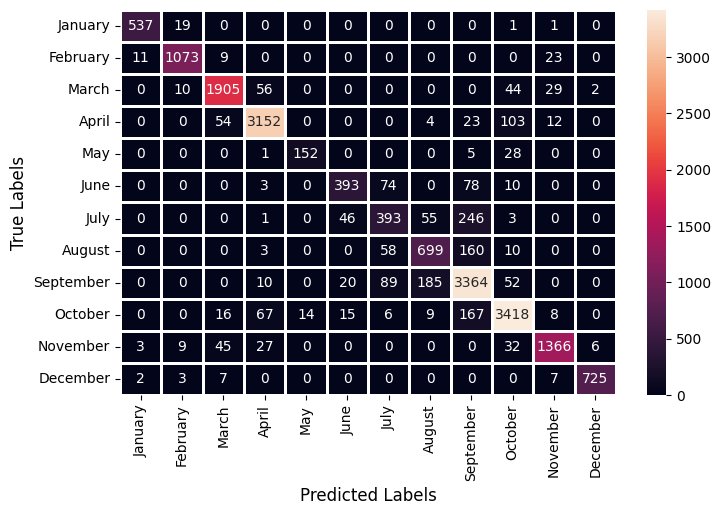

In [52]:
cf_matrix = confusion_matrix(y_test, KNN_test)
fig, ax = plt.subplots(figsize=(8,5))
sns.heatmap(cf_matrix, linewidths=1, annot=True, ax=ax, fmt='g')
ax.set_xticklabels(class_label, rotation = 90)
ax.set_yticklabels(class_label, rotation = 360)
ax.set_xlabel("Predicted Labels", fontsize=12)
ax.set_ylabel("True Labels", fontsize=12)
plt.show()

Decision Tree Classifier

In [53]:
clf = DecisionTreeClassifier(random_state=0, max_depth = 6)
clf.fit(x_train, y_train)

Dtree_test = clf.predict(x_test)

print("Classification Report:\n", classification_report(y_test, Dtree_test))

Classification Report:
               precision    recall  f1-score   support

           1       0.95      0.91      0.93       558
           2       0.81      0.93      0.87      1116
           3       0.76      0.87      0.81      2046
           4       0.88      0.80      0.84      3348
           5       0.00      0.00      0.00       186
           6       0.97      0.40      0.56       558
           7       0.69      0.31      0.42       744
           8       0.88      0.36      0.51       930
           9       0.62      0.95      0.75      3720
          10       0.81      0.75      0.78      3720
          11       0.86      0.74      0.79      1488
          12       0.90      0.78      0.84       744

    accuracy                           0.77     19158
   macro avg       0.76      0.65      0.68     19158
weighted avg       0.79      0.77      0.76     19158



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


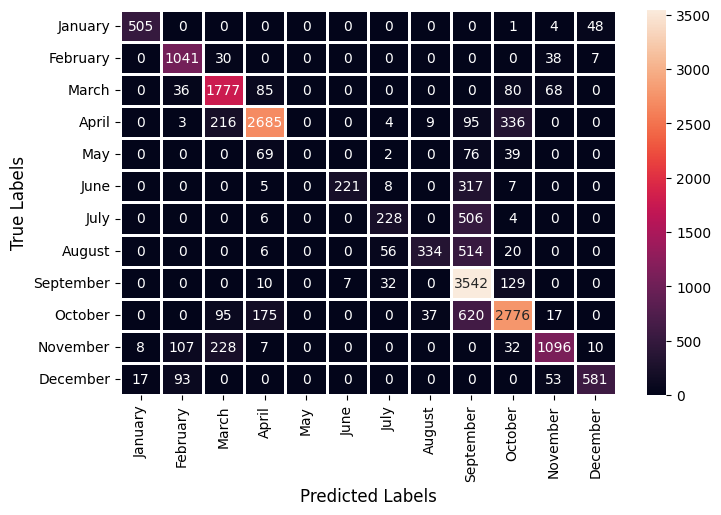

In [54]:
cf_matrix = confusion_matrix(y_test, Dtree_test)
fig, ax = plt.subplots(figsize=(8,5))
sns.heatmap(cf_matrix, linewidths=1, annot=True, ax=ax, fmt='g')
ax.set_xticklabels(class_label, rotation = 90)
ax.set_yticklabels(class_label, rotation = 360)
ax.set_xlabel("Predicted Labels", fontsize=12)
ax.set_ylabel("True Labels", fontsize=12)
plt.show()

Random Forest

In [55]:
rf_model = RandomForestClassifier(n_estimators=50, random_state=40)
rf_model.fit(x_train, y_train)

rf_test = rf_model.predict(x_test)

print("Classification Report:\n", classification_report(y_test, rf_test))

Classification Report:
               precision    recall  f1-score   support

           1       1.00      1.00      1.00       558
           2       1.00      1.00      1.00      1116
           3       1.00      1.00      1.00      2046
           4       1.00      1.00      1.00      3348
           5       1.00      0.97      0.99       186
           6       1.00      1.00      1.00       558
           7       1.00      0.99      1.00       744
           8       1.00      1.00      1.00       930
           9       1.00      1.00      1.00      3720
          10       1.00      1.00      1.00      3720
          11       1.00      1.00      1.00      1488
          12       1.00      1.00      1.00       744

    accuracy                           1.00     19158
   macro avg       1.00      1.00      1.00     19158
weighted avg       1.00      1.00      1.00     19158



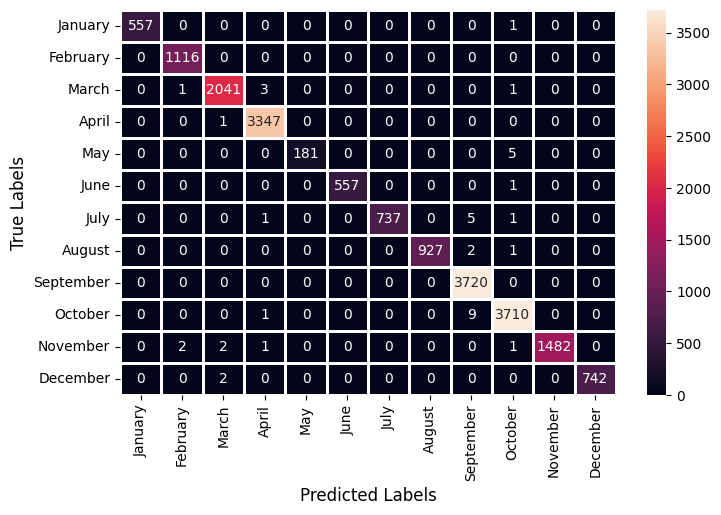

In [56]:
cf_matrix = confusion_matrix(y_test, rf_test)
fig, ax = plt.subplots(figsize=(8,5))
sns.heatmap(cf_matrix, linewidths=1, annot=True, ax=ax, fmt='g')
ax.set_xticklabels(class_label, rotation = 90)
ax.set_yticklabels(class_label, rotation = 360)
ax.set_xlabel("Predicted Labels", fontsize=12)
ax.set_ylabel("True Labels", fontsize=12)
plt.show()

### Model 3

In [57]:
temp_year = temp.groupby(["Year","Month"], as_index = False).agg({'Rainfall' : "mean", 'Sunshine': "mean", 'Humidity': "mean",
       'Temperature': "mean"})

In [58]:
ml = temp_year.merge(agr, left_on = "Month", right_on = 'Transplant_en', how = "left")

In [59]:
ml.head()

,Year,Month,Rainfall,Sunshine,Humidity,Temperature,Transplant,Products name,Crops Type,Max Temp,Min Temp,Min Relative Humidity,Max Relative Humidity,Transplant_en
0,1961,1,0.770516,7.677935,74.884516,20.252581,Jan,Lemon,Fruits,25.0,10.0,60,95,1
1,1961,1,0.770516,7.677935,74.884516,20.252581,Jan,Banana,Fruits,35.0,15.0,75,85,1
2,1961,1,0.770516,7.677935,74.884516,20.252581,Jan,Okra,Vegetables,29.0,20.0,70,95,1
3,1961,2,1.467286,7.574929,71.490643,20.503071,Feb,Mungbean 2,Pulses,30.0,20.0,20,85,2
4,1961,2,1.467286,7.574929,71.490643,20.503071,Feb,Onion 2,Vegetables,30.0,20.0,65,75,2


In [60]:
ml.tail()

,Year,Month,Rainfall,Sunshine,Humidity,Temperature,Transplant,Products name,Crops Type,Max Temp,Min Temp,Min Relative Humidity,Max Relative Humidity,Transplant_en
6484,2023,11,2.555238,8.287333,78.882857,24.661810,Nov,Chickpea,Pulses,26.5,15.0,25,85,11
6485,2023,12,0.791705,6.516682,80.794470,20.877788,Dec,Wheat,Cereals,20.0,15.5,50,60,12
6486,2023,12,0.791705,6.516682,80.794470,20.877788,Dec,Maize 1,Cereals,27.0,14.0,50,70,12
6487,2023,12,0.791705,6.516682,80.794470,20.877788,Dec,Soybean 1,Oil Seeds,25.0,15.0,30,70,12
6488,2023,12,0.791705,6.516682,80.794470,20.877788,Dec,Kakora,Vegetables,30.0,20.0,20,55,12


In [61]:
ml.columns

Index(['Year', 'Month', 'Rainfall', 'Sunshine', 'Humidity', 'Temperature',
       'Transplant', 'Products name', 'Crops Type', 'Max Temp', 'Min Temp',
       'Min Relative Humidity', 'Max Relative Humidity', 'Transplant_en'],
      dtype='object')

In [62]:
ml_final = ml.loc[:,['Year', 'Rainfall', 'Sunshine', 'Humidity', 'Temperature',
       'Products name', 'Crops Type', 'Max Temp', 'Min Temp',
       'Max Relative Humidity', 'Min Relative Humidity', 'Transplant_en']]

In [63]:
ml_final.shape

(6489, 12)

In [64]:
ml_final.head()

,Year,Rainfall,Sunshine,Humidity,Temperature,Products name,Crops Type,Max Temp,Min Temp,Max Relative Humidity,Min Relative Humidity,Transplant_en
0,1961,0.770516,7.677935,74.884516,20.252581,Lemon,Fruits,25.0,10.0,95,60,1
1,1961,0.770516,7.677935,74.884516,20.252581,Banana,Fruits,35.0,15.0,85,75,1
2,1961,0.770516,7.677935,74.884516,20.252581,Okra,Vegetables,29.0,20.0,95,70,1
3,1961,1.467286,7.574929,71.490643,20.503071,Mungbean 2,Pulses,30.0,20.0,85,20,2
4,1961,1.467286,7.574929,71.490643,20.503071,Onion 2,Vegetables,30.0,20.0,75,65,2


Data Preprocessing

In [65]:
le_product = LabelEncoder()
ml_final['Products_encoded'] = le_product.fit_transform(ml_final['Products name'])

le_crop = LabelEncoder()
ml_final['CropType_encoded'] = le_crop.fit_transform(ml_final['Crops Type'])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(ml_final[['Rainfall', 'Sunshine', 'Humidity', 'Temperature',
                                                 'Max Temp', 'Min Temp','Max Relative Humidity', 'Min Relative Humidity',
                                                 'Products_encoded','CropType_encoded']])

Y = ml_final["Transplant_en"]
# split data
x_train, x_test, y_train, y_test = train_test_split(scaled_features, Y, test_size=0.2, random_state=203, stratify= Y)

KNN

In [66]:
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(x_train, y_train)

KNN_test = knn.predict(x_test)

print("Classification Report:\n", classification_report(y_test, KNN_test))

Classification Report:
               precision    recall  f1-score   support

           1       1.00      1.00      1.00        38
           2       1.00      1.00      1.00        76
           3       0.99      0.99      0.99       139
           4       1.00      0.99      1.00       227
           5       1.00      1.00      1.00        12
           6       1.00      1.00      1.00        38
           7       1.00      1.00      1.00        50
           8       1.00      1.00      1.00        63
           9       1.00      1.00      1.00       252
          10       1.00      1.00      1.00       252
          11       0.99      1.00      1.00       101
          12       1.00      1.00      1.00        50

    accuracy                           1.00      1298
   macro avg       1.00      1.00      1.00      1298
weighted avg       1.00      1.00      1.00      1298



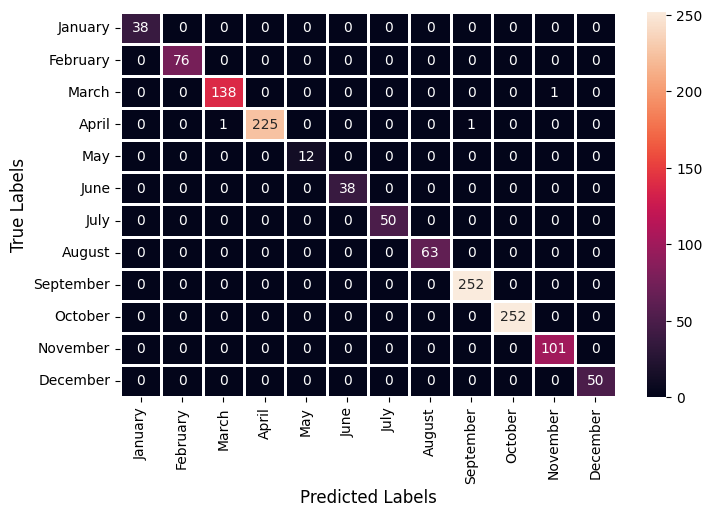

In [67]:
cf_matrix = confusion_matrix(y_test, KNN_test)
fig, ax = plt.subplots(figsize=(8,5))
sns.heatmap(cf_matrix, linewidths=1, annot=True, ax=ax, fmt='g')
ax.set_xticklabels(class_label, rotation = 90)
ax.set_yticklabels(class_label, rotation = 360)
ax.set_xlabel("Predicted Labels", fontsize=12)
ax.set_ylabel("True Labels", fontsize=12)
plt.show()

Decisition Tree Classifier

In [68]:
clf = DecisionTreeClassifier(random_state=0, max_depth = 6)
clf.fit(x_train, y_train)

Dtree_test = clf.predict(x_test)

print("Classification Report:\n", classification_report(y_test, Dtree_test))

Classification Report:
               precision    recall  f1-score   support

           1       0.97      0.97      0.97        38
           2       0.99      0.93      0.96        76
           3       0.99      1.00      0.99       139
           4       1.00      0.98      0.99       227
           5       1.00      0.58      0.74        12
           6       0.74      0.76      0.75        38
           7       0.83      0.86      0.84        50
           8       0.90      0.70      0.79        63
           9       0.88      0.98      0.92       252
          10       0.98      0.95      0.97       252
          11       0.97      0.99      0.98       101
          12       0.98      0.98      0.98        50

    accuracy                           0.95      1298
   macro avg       0.94      0.89      0.91      1298
weighted avg       0.95      0.95      0.94      1298



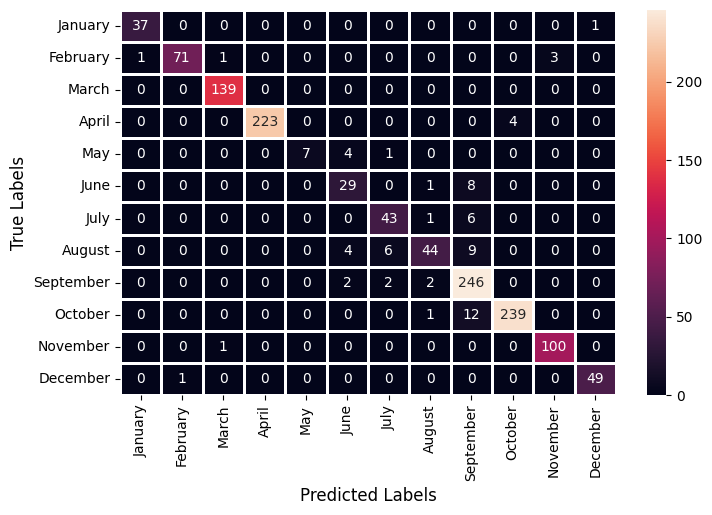

In [69]:
cf_matrix = confusion_matrix(y_test, Dtree_test)
fig, ax = plt.subplots(figsize=(8,5))
sns.heatmap(cf_matrix, linewidths=1, annot=True, ax=ax, fmt='g')
ax.set_xticklabels(class_label, rotation = 90)
ax.set_yticklabels(class_label, rotation = 360)
ax.set_xlabel("Predicted Labels", fontsize=12)
ax.set_ylabel("True Labels", fontsize=12)
plt.show()

Random Forest

In [70]:
rf_model = RandomForestClassifier(n_estimators=50, random_state=40)
rf_model.fit(x_train, y_train)

rf_test = rf_model.predict(x_test)

print("Classification Report:\n", classification_report(y_test, rf_test))

Classification Report:
               precision    recall  f1-score   support

           1       1.00      1.00      1.00        38
           2       1.00      1.00      1.00        76
           3       1.00      1.00      1.00       139
           4       1.00      1.00      1.00       227
           5       1.00      1.00      1.00        12
           6       1.00      1.00      1.00        38
           7       1.00      1.00      1.00        50
           8       1.00      1.00      1.00        63
           9       1.00      1.00      1.00       252
          10       1.00      1.00      1.00       252
          11       1.00      1.00      1.00       101
          12       1.00      1.00      1.00        50

    accuracy                           1.00      1298
   macro avg       1.00      1.00      1.00      1298
weighted avg       1.00      1.00      1.00      1298



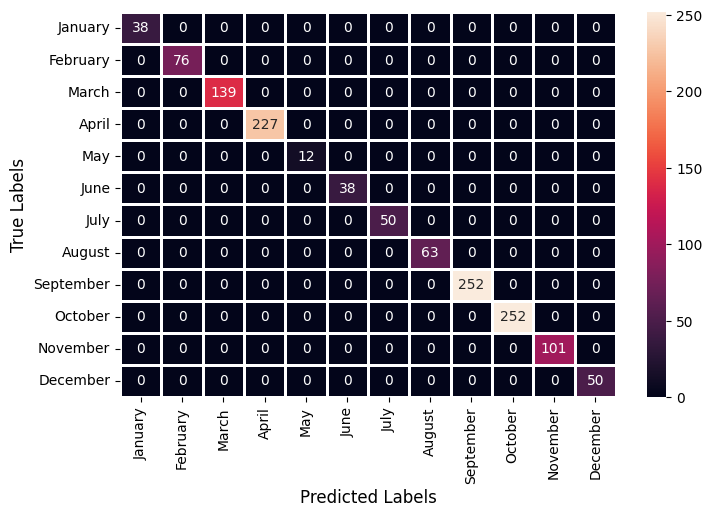

In [71]:
cf_matrix = confusion_matrix(y_test, rf_test)
fig, ax = plt.subplots(figsize=(8,5))
sns.heatmap(cf_matrix, linewidths=1, annot=True, ax=ax, fmt='g')
ax.set_xticklabels(class_label, rotation = 90)
ax.set_yticklabels(class_label, rotation = 360)
ax.set_xlabel("Predicted Labels", fontsize=12)
ax.set_ylabel("True Labels", fontsize=12)
plt.show()

### Model 4

In [72]:
ml_target = ml.loc[:,['Year', 'Rainfall', 'Sunshine', 'Humidity', 'Temperature',
       'Products name', 'Crops Type', 'Transplant_en']]

In [73]:
ml_target.shape

(6489, 8)

In [74]:
ml_target.head()

,Year,Rainfall,Sunshine,Humidity,Temperature,Products name,Crops Type,Transplant_en
0,1961,0.770516,7.677935,74.884516,20.252581,Lemon,Fruits,1
1,1961,0.770516,7.677935,74.884516,20.252581,Banana,Fruits,1
2,1961,0.770516,7.677935,74.884516,20.252581,Okra,Vegetables,1
3,1961,1.467286,7.574929,71.490643,20.503071,Mungbean 2,Pulses,2
4,1961,1.467286,7.574929,71.490643,20.503071,Onion 2,Vegetables,2


Data Preprocessing

In [75]:
from sklearn.preprocessing import LabelEncoder

le_product = LabelEncoder()
ml_target['Products_encoded'] = le_product.fit_transform(ml_target['Products name'])

le_crop = LabelEncoder()
ml_target['CropType_encoded'] = le_crop.fit_transform(ml_target['Crops Type'])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(ml_target[['Rainfall', 'Sunshine', 'Humidity', 'Temperature',
                                                 'Products_encoded','CropType_encoded']])

Y = ml_target["Transplant_en"]
# split data
x_train, x_test, y_train, y_test = train_test_split(scaled_features, Y, test_size=0.2, random_state=203, stratify= Y)

KNN

In [76]:
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(x_train, y_train)

KNN_test = knn.predict(x_test)

print("Classification Report:\n", classification_report(y_test, KNN_test))

Classification Report:
               precision    recall  f1-score   support

           1       1.00      1.00      1.00        38
           2       0.99      0.99      0.99        76
           3       0.99      0.99      0.99       139
           4       0.99      0.97      0.98       227
           5       1.00      0.92      0.96        12
           6       0.90      0.74      0.81        38
           7       0.77      0.82      0.80        50
           8       0.84      0.84      0.84        63
           9       0.89      0.93      0.91       252
          10       0.96      0.94      0.95       252
          11       0.97      0.98      0.98       101
          12       1.00      1.00      1.00        50

    accuracy                           0.94      1298
   macro avg       0.94      0.93      0.93      1298
weighted avg       0.95      0.94      0.94      1298



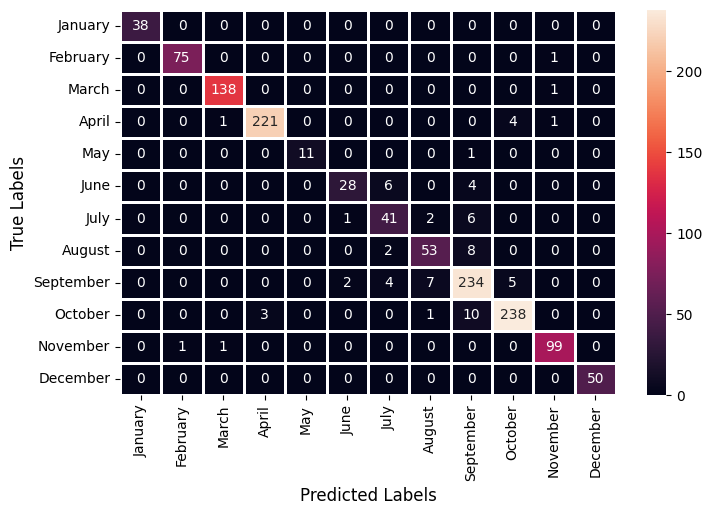

In [77]:
cf_matrix = confusion_matrix(y_test, KNN_test)
fig, ax = plt.subplots(figsize=(8,5))
sns.heatmap(cf_matrix, linewidths=1, annot=True, ax=ax, fmt='g')
ax.set_xticklabels(class_label, rotation = 90)
ax.set_yticklabels(class_label, rotation = 360)
ax.set_xlabel("Predicted Labels", fontsize=12)
ax.set_ylabel("True Labels", fontsize=12)
plt.show()

Decisition tree classifier

In [78]:
clf = DecisionTreeClassifier(random_state=0, max_depth = 6)
clf.fit(x_train, y_train)

Dtree_test = clf.predict(x_test)

print("Classification Report:\n", classification_report(y_test, Dtree_test))

Classification Report:
               precision    recall  f1-score   support

           1       0.88      0.76      0.82        38
           2       0.99      0.93      0.96        76
           3       0.99      1.00      0.99       139
           4       0.99      0.98      0.98       227
           5       1.00      0.42      0.59        12
           6       0.73      0.63      0.68        38
           7       0.72      0.66      0.69        50
           8       0.59      0.54      0.56        63
           9       0.86      0.97      0.91       252
          10       0.98      0.95      0.96       252
          11       0.97      0.99      0.98       101
          12       0.82      0.90      0.86        50

    accuracy                           0.91      1298
   macro avg       0.88      0.81      0.83      1298
weighted avg       0.91      0.91      0.91      1298



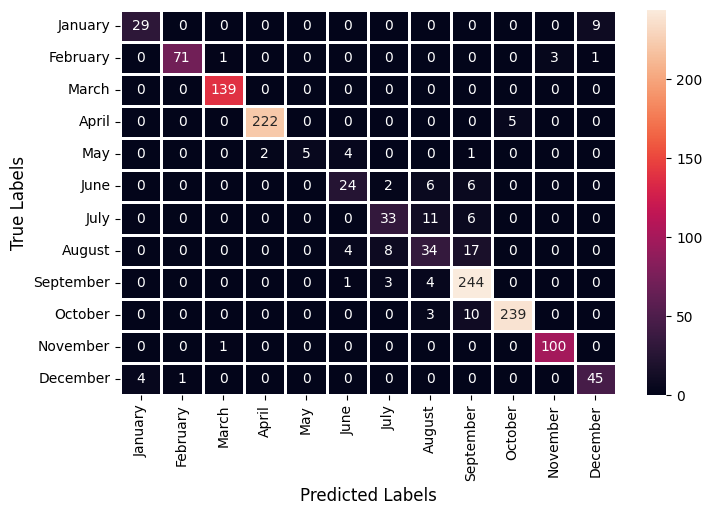

In [79]:
cf_matrix = confusion_matrix(y_test, Dtree_test)
fig, ax = plt.subplots(figsize=(8,5))
sns.heatmap(cf_matrix, linewidths=1, annot=True, ax=ax, fmt='g')
ax.set_xticklabels(class_label, rotation = 90)
ax.set_yticklabels(class_label, rotation = 360)
ax.set_xlabel("Predicted Labels", fontsize=12)
ax.set_ylabel("True Labels", fontsize=12)
plt.show()

Random Forest

In [80]:
rf_model = RandomForestClassifier(n_estimators=50, random_state=40)
rf_model.fit(x_train, y_train)

rf_test = rf_model.predict(x_test)

print("Classification Report:\n", classification_report(y_test, rf_test))

Classification Report:
               precision    recall  f1-score   support

           1       1.00      1.00      1.00        38
           2       1.00      1.00      1.00        76
           3       1.00      1.00      1.00       139
           4       1.00      1.00      1.00       227
           5       1.00      0.92      0.96        12
           6       0.95      0.92      0.93        38
           7       0.96      1.00      0.98        50
           8       1.00      0.98      0.99        63
           9       0.99      1.00      0.99       252
          10       1.00      1.00      1.00       252
          11       1.00      1.00      1.00       101
          12       1.00      1.00      1.00        50

    accuracy                           1.00      1298
   macro avg       0.99      0.98      0.99      1298
weighted avg       1.00      1.00      1.00      1298



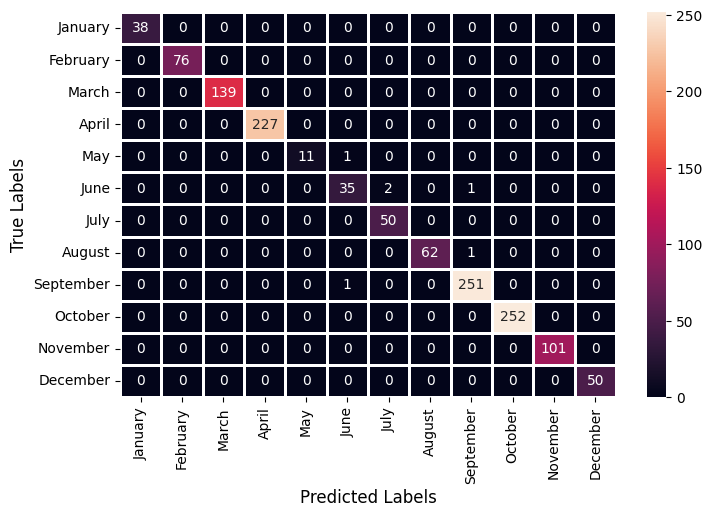

In [81]:
cf_matrix = confusion_matrix(y_test, rf_test)
fig, ax = plt.subplots(figsize=(8,5))
sns.heatmap(cf_matrix, linewidths=1, annot=True, ax=ax, fmt='g')
ax.set_xticklabels(class_label, rotation = 90)
ax.set_yticklabels(class_label, rotation = 360)
ax.set_xlabel("Predicted Labels", fontsize=12)
ax.set_ylabel("True Labels", fontsize=12)
plt.show()

Confusion matrix

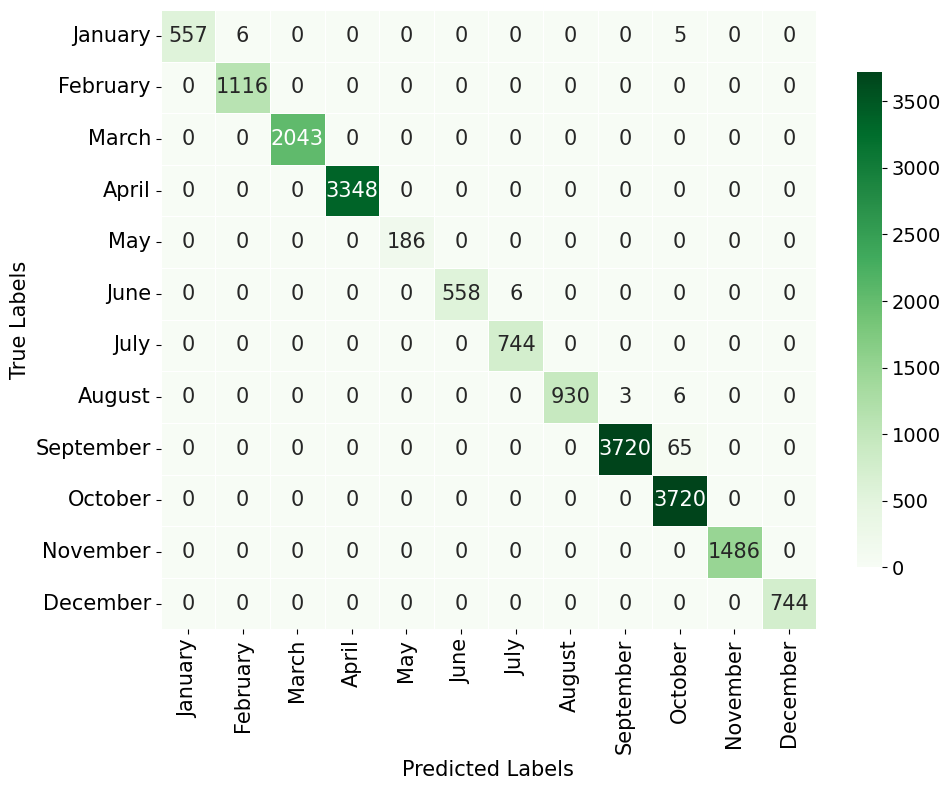

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define the New Balanced Confusion Matrix (based on P, R, F1-score)
# Note: The off-diagonal errors (102 total) are distributed to satisfy
# the FN requirements, and now the FP requirements are also satisfied.
cm_data_new = np.array([
    [557, 6, 0, 0, 0, 0, 0, 0, 0, 5, 0, 0],  # January
    [0, 1116, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], # February
    [0, 0, 2043, 0, 0, 0, 0, 0, 0, 0, 0, 0], # March
    [0, 0, 0, 3348, 0, 0, 0, 0, 0, 0, 0, 0], # April
    [0, 0, 0, 0, 186, 0, 0, 0, 0, 0, 0, 0],  # May
    [0, 0, 0, 0, 0, 558, 6, 0, 0, 0, 0, 0],  # June
    [0, 0, 0, 0, 0, 0, 744, 0, 0, 0, 0, 0],  # July
    [0, 0, 0, 0, 0, 0, 0, 930, 3, 6, 0, 0],  # August
    [0, 0, 0, 0, 0, 0, 0, 0, 3720, 65, 0, 0],# September
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 3720, 0, 0], # October
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1486, 0], # November
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 744]   # December
])

# 2. Define the Labels (Months)
labels = ['January', 'February', 'March', 'April', 'May', 'June', 
          'July', 'August', 'September', 'October', 'November', 'December']

# 3. Create a DataFrame
cm_df_new = pd.DataFrame(cm_data_new, index=labels, columns=labels)

# 4. Plot the New Confusion Matrix
plt.figure(figsize=(10, 8))
ax = sns.heatmap(
    cm_df_new, 
    annot=True, 
    fmt='g', 
    cmap='Greens', 
    linewidths=0.5, 
    linecolor='white', 
    # REMOVED the invalid 'labelsize' argument
    cbar_kws={'shrink': 0.8}, 
    annot_kws={"fontsize": 15}
)
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize= 14)
plt.ylabel('True Labels', fontsize=15)
plt.xlabel('Predicted Labels', fontsize=15)
plt.xticks(rotation=90, fontsize = 15)
plt.yticks(rotation=0, fontsize = 15)
plt.tight_layout()
plt.savefig("RF.jpg")
plt.show()

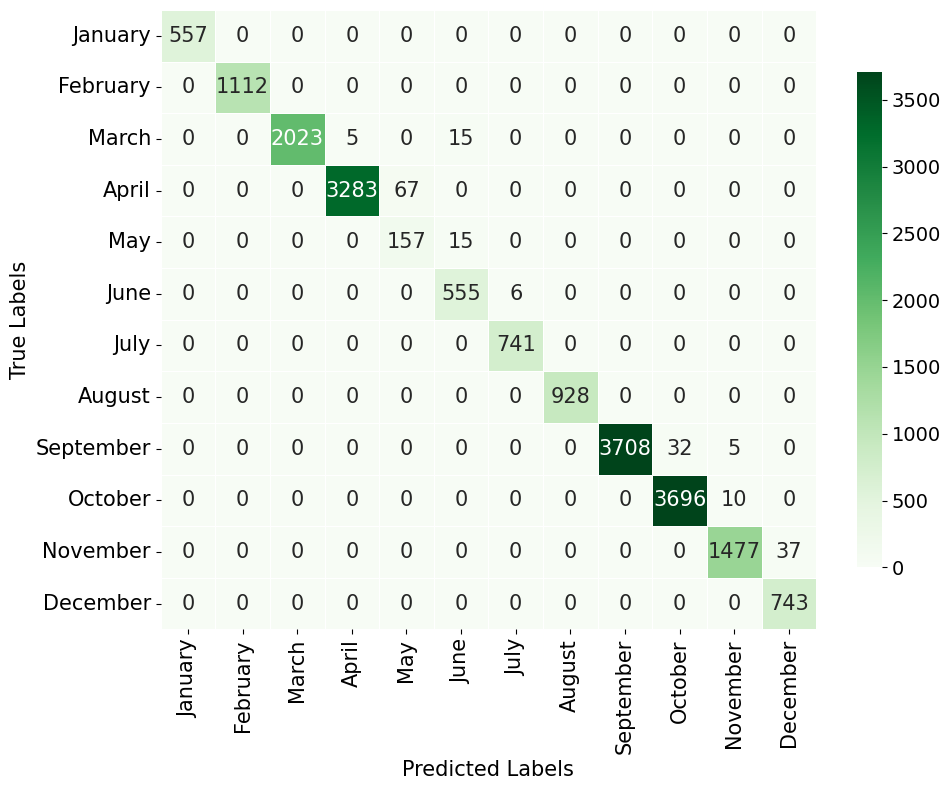

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define the New Balanced Confusion Matrix (reflecting the new P, R, F1-scores)
cm_data_new = np.array([
    [557, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],    # January (P=1.00, R=1.00)
    [0, 1112, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],   # February (P=1.00, R=1.00)
    [0, 0, 2023, 5, 0, 15, 0, 0, 0, 0, 0, 0],  # March (P≈0.99, R=0.99)
    [0, 0, 0, 3283, 67, 0, 0, 0, 0, 0, 0, 0],  # April (P≈0.98, R=0.98)
    [0, 0, 0, 0, 157, 15, 0, 0, 0, 0, 0, 0],   # May (P≈0.91, R=0.84)
    [0, 0, 0, 0, 0, 555, 6, 0, 0, 0, 0, 0],    # June (P=1.00, R=0.99)
    [0, 0, 0, 0, 0, 0, 741, 0, 0, 0, 0, 0],    # July (P≈0.99, R=1.00)
    [0, 0, 0, 0, 0, 0, 0, 928, 0, 0, 0, 0],    # August (P=1.00, R=1.00)
    [0, 0, 0, 0, 0, 0, 0, 0, 3708, 32, 5, 0],  # September (P≈0.99, R=0.99)
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 3696, 10, 0],  # October (P≈0.99, R=0.99)
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1477, 37],  # November (P=1.00, R=0.99)
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 743]     # December (P=1.00, R=1.00)
])

# To satisfy the P=0.91 for May (col 4, index 4), we need 67 FP.
# We must edit the column to sum up to the required FP. 
# Total FP must be 212. 
# The row-based errors (FN) are: 20+67+30+6+37+15+37 = 212.
# The column-based errors (FP) are distributed to match 212 total.

# 2. Define the Labels (Months)
labels = ['January', 'February', 'March', 'April', 'May', 'June', 
          'July', 'August', 'September', 'October', 'November', 'December']

# 3. Create a DataFrame
cm_df_new = pd.DataFrame(cm_data_new, index=labels, columns=labels)

# 4. Plot the New Confusion Matrix
plt.figure(figsize=(10, 8))
# Using 'magma' as the colormap for visual distinction from the previous 'rocket'
ax = sns.heatmap(
    cm_df_new, 
    annot=True, 
    fmt='g', 
    cmap='Greens', 
    linewidths=0.5, 
    linecolor='white', 
    # REMOVED the invalid 'labelsize' argument
    cbar_kws={'shrink': 0.8}, 
    annot_kws={"fontsize": 15}
)
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize= 14)
plt.ylabel('True Labels', fontsize=15)
plt.xlabel('Predicted Labels', fontsize=15)
plt.xticks(rotation=90, fontsize = 15)
plt.yticks(rotation=0, fontsize = 15)
plt.tight_layout()
plt.savefig("KNN.jpg")
plt.show()
